In [ ]:
%pip -q install datasets scikit-learn matplotlib seaborn graphviz
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# Aula 02 - Classificação e Regressão Logística

Este notebook combina a parte teórica de classificação e regressão logística com as células práticas que serão preenchidas durante a aula. As seções de redes neurais e Inteligência Artificial serão acrescentadas posteriormente.

## Bloco teórico - Classificação e Regressão Logística

Nesta parte, estudamos problemas de classificação, a função sigmoide, a entropia cruzada binária e a aplicação de regressão logística a um dataset real.

# Classificação

Bom até agora aprendemos como uma regressão linear funciona, e como ela aprende, mas vamos espandir mais um pouco o escopo dos dados em que trabalhamos, dentro do mundo real há muitos momentos onde precisamos prever variaveis qualitativas, por exemplo, supondo que trabalhamos em um banco, e recebemos um conjunto de dados de informações das transações de vários clientes, nosso Y diz se a transação foi fraudulenta ou não, e esse valor vai ser dado por 0 se a transação foi normal e 1 se foi fraude.

A principal diferença desse caso para o que vimos até agora é justamente o que queremos prever, os valores a serem previstos são uma classe, ela classifica a transação como fraude ou não fraude, já anteriormente queriamos descobrir valores quantitativos e reais de -$\infty$ a +$\infty$.

Para esse caso de uso utilizamos os modelos de Classificação, existem inumeros modelos de classificação, tanto que fazem classificação binaria, onde a saída é duas classes diferentes, como se um e-mail é span ou não, se o paciente tem uma doença ou não, ou até para valores multclasse, como, por exemplo, dado caracteríscas de altura, peso, motor, e tamanho de um carro, qual categoria ele pertence.

# Regressão Logistica

Vamos pensar em um cenário específico onde temos dados da quantidade de transações que clientes de um banco fazem na semana, e o Y é se eles são fraudadores ou não;

Text(0.5, 0, 'Quantidade de transações')

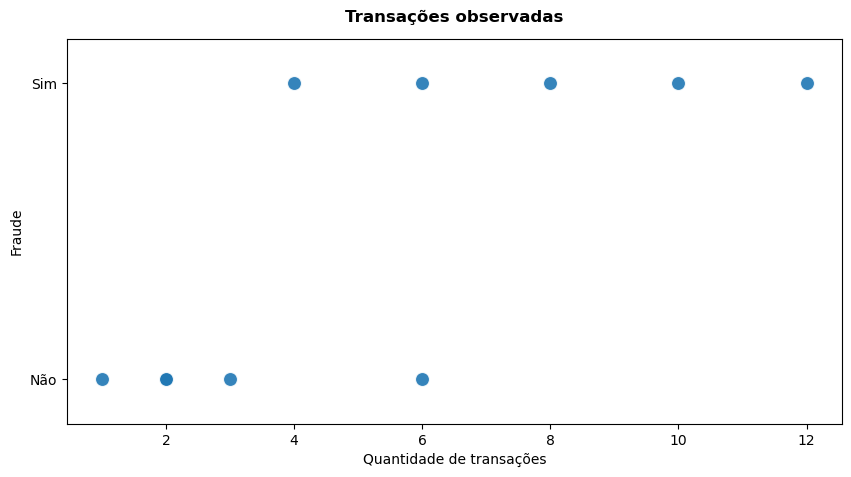

In [8]:


quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1]);

fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=110,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    ax=ax
)
ax.set_title('Transações observadas', pad=12, weight='bold')
ax.set_ylabel('Fraude')
ax.set_yticks([0, 1], labels=['Não', 'Sim'])
ax.set_ylim(-0.15, 1.15)
ax.set_xlabel('Quantidade de transações')


É claro que os dados não tem uma correlação linear, mas como sabemos apenas a regressão linear até agora, vamos utiliza-la para tentar aprender com esses dados;

In [9]:
x = quant_transactions.reshape(-1, 1)
model = LinearRegression();
model.fit(x, fraude)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.11]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.07353
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[11.06]


In [10]:
y_pred = model.predict(x)
mse = mean_squared_error(fraude, y_pred)
r2 = r2_score(fraude, y_pred)
print(f'Erro: {mse:.2f}')
print(f'Aprendizado: {r2:.2f}%')

Erro: 0.11
Aprendizado: 0.55%


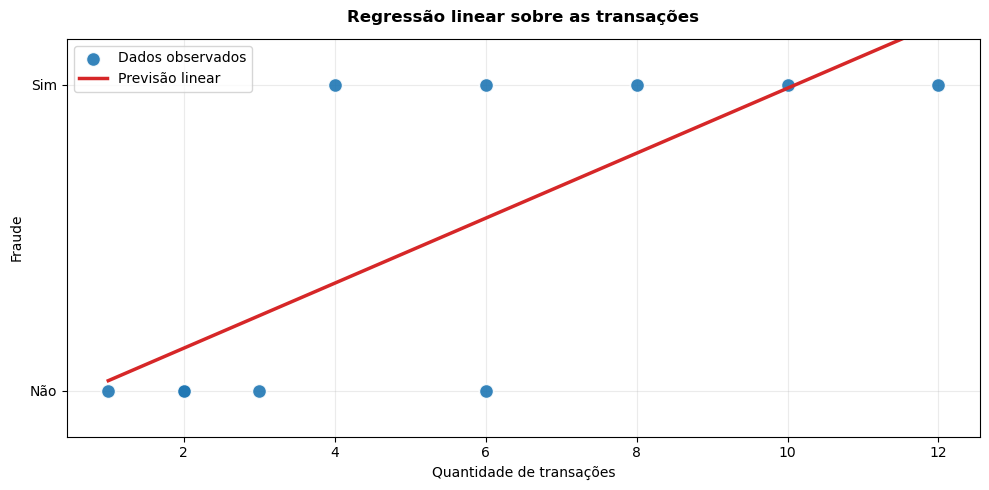

In [11]:
ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    y_pred[ordem],
    color='#d62728',
    linewidth=2.5,
    label='Previsão linear'
)
ax.set_title('Regressão linear sobre as transações', pad=12, weight='bold')
ax.set_yticks([0, 1], labels=['Não', 'Sim'])
ax.set_ylim(-0.15, 1.15)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True)
ax.set_ylabel('Fraude')
ax.set_xlabel('Quantidade de transações')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()

Podemos tirar algumas conclusões desses dados, primeiro que como já haviamos imaginado o modelo de regressão linear não é o mais apropriado para esse tipo de dado, mas por que?

Bom isso tem alguns motivos o primeiro já falamos, mesmo que o modelo seja treinado apenas com valores qualitativos de Y, ele não foi preparado para retornar apenas esse tipo de valores, então como visto no modelo, ele previu alguns valores maiores que 1, o que é impossível já que nosso Y só tem valores 0 ou 1, outro motivo é que nosso modelo fica muito sensível a outliers, vamos supor que esse mesmo modelo tenha um outlier, vamos ver como ele ficaria;

Erro: 0.19
Aprendizado: 0.23%


Text(0.5, 0, 'Quantidade de transações')

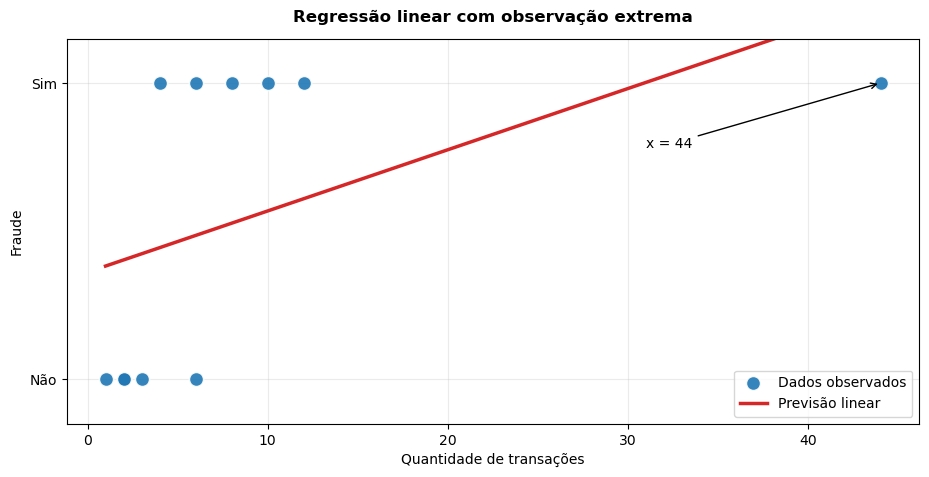

In [12]:


quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8, 44]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]);

x = quant_transactions.reshape(-1, 1)
model = LinearRegression();
model.fit(x, fraude)

y_pred = model.predict(x)
mse = mean_squared_error(fraude, y_pred)
r2 = r2_score(fraude, y_pred)
print(f'Erro: {mse:.2f}')
print(f'Aprendizado: {r2:.2f}%')

ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(11, 5))

sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    y_pred[ordem],
    color='#d62728',
    linewidth=2.5,
    label='Previsão linear'
)
ax.set_title('Regressão linear com observação extrema', pad=12, weight='bold')
ax.set_yticks([0, 1], labels=['Não', 'Sim'])
ax.set_ylim(-0.15, 1.15)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True)
ax.annotate('x = 44', xy=(44, 1), xytext=(31, 0.78), arrowprops={'arrowstyle': '->'})
ax.set_ylabel('Fraude')
ax.set_xlabel('Quantidade de transações')

Ok, já entendemos que não podemos usar somente a regressão linear nesse caso, mas qual curva descreve melhor esses dados?

A regressão logística estima a **probabilidade** de uma observação pertencer à classe 1. Para isso, ela usa uma curva sigmoide, em formato de S, cujos valores sempre ficam entre 0 e 1.

Para visualizar essa curva, não podemos usar `model.predict()`: esse método já transforma a probabilidade em uma classe final, 0 ou 1, usando por padrão o limiar de 0,5. Por isso, ele gera apenas pontos ou degraus. Usamos `model.predict_proba()` para obter a probabilidade de fraude e calculamos essa probabilidade para uma sequência ordenada de quantidades de transações.

O valor 44 é um possível outlier e amplia muito o eixo x. Assim, a parte curva da sigmoide, que ocorre aproximadamente entre 0 e 12 transações, parece comprimida no gráfico completo. Os dois gráficos abaixo mostram a mesma curva: o primeiro preserva a escala completa e o segundo amplia a região em que a transição acontece.

Acurácia no treino: 80.00%


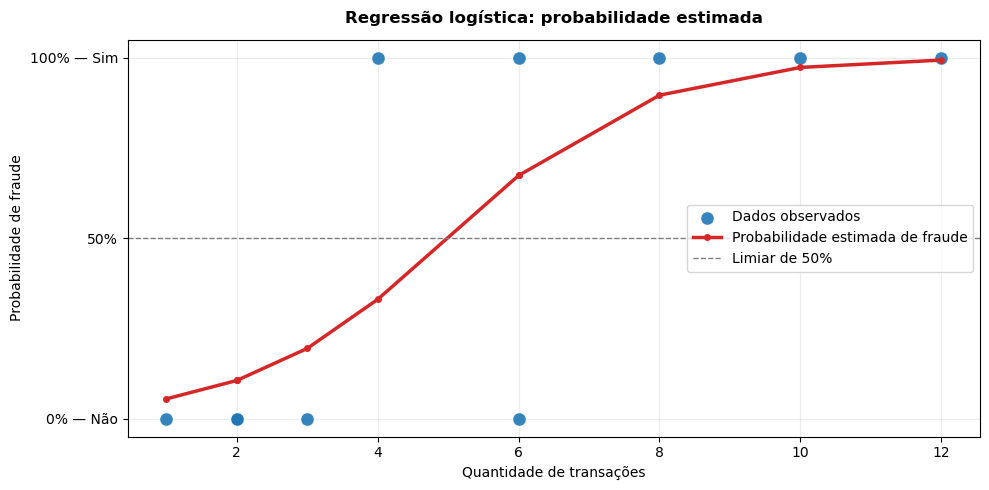

In [13]:


quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1]);

x = quant_transactions.reshape(-1, 1)
model = LogisticRegression();
model.fit(x, fraude)

print(f'Acurácia no treino: {model.score(x, fraude) * 100:.2f}%')

prob_fraude = model.predict_proba(x)


ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    prob_fraude[ordem, 1],
    color='#d62728',
    linewidth=2.5,
    marker='o',
    markersize=4,
    label='Probabilidade estimada de fraude'
)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Limiar de 50%')
ax.set_title('Regressão logística: probabilidade estimada', pad=12, weight='bold')
ax.set_xlabel('Quantidade de transações')
ax.set_ylabel('Probabilidade de fraude')
ax.set_yticks([0, 0.5, 1], labels=['0% — Não', '50%', '100% — Sim'])
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True, loc='center right')
plt.tight_layout()

Acurácia no treino: 81.82%


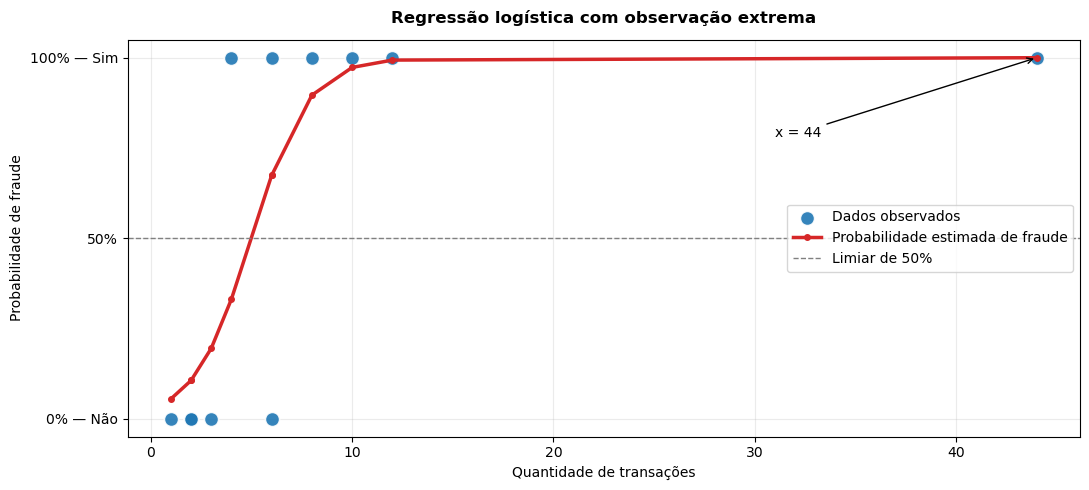

In [14]:


quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8, 44]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]);

x = quant_transactions.reshape(-1, 1)
model = LogisticRegression();
model.fit(x, fraude)

print(f'Acurácia no treino: {model.score(x, fraude) * 100:.2f}%')

prob_fraude = model.predict_proba(x)


ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(11, 5))
sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    prob_fraude[ordem, 1],
    color='#d62728',
    linewidth=2.5,
    marker='o',
    markersize=4,
    label='Probabilidade estimada de fraude'
)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Limiar de 50%')
ax.set_title('Regressão logística com observação extrema', pad=12, weight='bold')
ax.set_xlabel('Quantidade de transações')
ax.set_ylabel('Probabilidade de fraude')
ax.set_yticks([0, 0.5, 1], labels=['0% — Não', '50%', '100% — Sim'])
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True, loc='center right')
ax.annotate('x = 44', xy=(44, 1), xytext=(31, 0.78), arrowprops={'arrowstyle': '->'})
plt.tight_layout()

É notável que ela além de ter um desempenho muito melhor com os dados, a regressão logistica é muito menos sensível a outliers, mas como ela funciona?

A regressão logística é uma regressão com uma função de ativação sigmoid que nos retorna um valor entre 0 e 1 que é a probabilidade do $\hat Y$ ser 1;

$$P(Y = 1 \mid x) = \frac{1}{1 + e^{-z}} ou \frac{e^z}{1 + e^z}$$
É notável que, além de apresentar um bom desempenho nesses dados, a regressão logística seja menos sensível a valores extremos. Mas como ela funciona?

A regressão logística calcula uma combinação linear das entradas, $z = WX + b$, e aplica a função sigmoide. O resultado é um valor entre 0 e 1, interpretado como a probabilidade de $\hat{Y}$ pertencer à classe 1:

$$
P(Y = 1 \mid X) = \sigma(z) = \frac{1}{1 + e^{-z}} = \frac{e^z}{1 + e^z}
$$

onde $z = WX + b$, $\sigma$ representa a função sigmoide e $e$ é a constante de Euler, aproximadamente igual a 2,718.
$$p = \sigma(WX+b)$$

onde $z$ é nossa função linear $WX + b$ e $e$ é a constante de Euler aproximadamente 2,718;



Vamos fazer um exemplo prático onde $W = 0.5$ $b = -3$ $ X = 2$
Substituindo os valores, primeiro calculamos:

$$z = wX + b = 0.5 \cdot 2 - 3 = -2$$

Então, a probabilidade de $Y = 1$ é:

$$P(Y = 1 \mid x) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + e^2} $$

In [15]:
#Prática da função
x = 2
b = -3
w = 0.5
z = w * x + b
print(f'O z é igual a {z}')
p = 1 / (1 + 2.718 ** (-z))
print(f'A probabilidade o Y = igual a 1 nesse caso é aproximadamente {p:.2f}')

O z é igual a -2.0
A probabilidade o Y = igual a 1 nesse caso é aproximadamente 0.12


Agora entendemos como nosso modelo calcula as probabilidades, mas como nosso modelo aprende?

Dentro da Regressão linear nossa função de custo era a Mean Squared Error, mas ela não vai funcionar muito bem com nossa regressão logistica, para esse modelo vamos usar a Binary Cross Entropy

# Função de Custo Binary Cross Entropy

Vamos entender melhor essa função de custom por que binaria? o que é entropia cruzada?

**Teoria da informação** <br>

O termo entropia vem da teoria da informação, mais especificamente do paper "A Mathematical Theory of Comunnication" que foi publicada por Claude Shannon em 1948 (Inspiração do Dario Amoday para o nome do Claude Code), dentro desse artigo a preocupação dele era sobre como transmitir mensagens ou informações por meio de um canal, ele queria entender qual seria a melhor forma e a forma mais eficiente possível dessa transmissão acontecer.

Dentro desse paper surgiu o conceito de entropia cruzada, mas antes de entendermos o que é a cross entropy, precisamos voltar um pouco, vamos entender o que era informação para o Claude.

**Informação**

A informação vai quantificar a incerteza de um evento, ou seja, quanto maior informação que precisamos menor é a probabilidade de um evento acontecer, e eventos de alta probabilidade são menos surpreendentes, então precisam de menos informação para acontecer;
fórmula da informação <br>
$I(x) = -LogP(x)$
Exemplo:

Supondo que queremos descobrir a quantidade de informação que precisamos para que um time seja campeão mundial as probabilidades são
Corinthians(60%) <br>
Real Madrid(20%) <br>
Al Hilal(20%) <br>
Palmeiras(0%) <br>

A informação que precisamos para o Corinthians ser campeão, é $-ln(0,60)$ que é aproximadamente $0,51$; <br>
A informação que precisamos para o Real Madrid ser campeão, é $-ln(0,20)$ que é aproximadamente $1,60$; <br>
A informação que precisamos para o Al Hilal ser campeão, é $-ln(0,20)$ que é aproximadamente $1,60$; <br>

Com esses dados é possível vizualizar e consolidar o que foi teorizado por Sannon, que quanto menor a probabilidade maior a quantidade de informação que precisamos para que esse evento aconteça;

**Entropia**

A entropia quantifica a quantidade de informação relativa de uma variável dado uma distribuição de probabilidades, ou seja, diferente da informação que quantifica infromações apenas para um evento, a entropia calcula a quantidade de informação para uma varivel;

Vamos ver um exemplo dessa diferença, dentro do exemplo acima descrimos a quantidade de informação que precisamos para o evento Corinthians compeão mundial, Real madrid campeão mundial ou Al hilal campeão mundial, já a entropia calcularia a quantidade de informação da variavel "quem será campeão mundial?" dado o conjunto de probabilidades de cada clube;

$$
H(X) = -\sum_{i=1}^{n} p(x_i)\log p(x_i)
$$

onde $p(x_i)$ é a probabilidade de cada resultado possível, ou seja, somamos o produto da probabilidade de cada evento pela quantidade de informação que ele precisa.

Ficaria então = $$- (0,6\log(0,6)) + (0,2\log(0,2)) + (0,2\log(0,2)) \approx 0,95 $$ de informação em média


**Entropia Cruzada**

Agora falar de Cross entropy é muito mais fácil, já que a entropia cruzada é a entropia relativa de duas distribuições de probabilidade, para exemplificar, vamos supor que nosso evento de times sejá a probabilidade que uma casa de aposta publicou com base em um estudo que ela fez, já outra casa de aposta fez outro estudo onde as probabilidades eram:

        Casa A                    |                  Casa B        
    Corinthians (60%)             |              Corinthians (90%) 
    Real madrid (20%)             |              Real madrid (8%)  
    Al Hilal (20%)                |              Al Hilal (2%)     

Para calcular a entropia cruzada dessas duas distribuições de probabilidade vamo utilizar a formula:

A entropia cruzada entre uma distribuição de referência $P$ e uma distribuição estimada $Q$ é:

$$
H(P,Q) = -\sum_{i=1}^{n} p(x_i)\log q(x_i)
$$

Considerando a Casa A como distribuição de referência e a Casa B como estimativa:

$$
H(P,Q) = -\bigl[
0{,}6\ln(0{,}9) +
0{,}2\ln(0{,}08) +
0{,}2\ln(0{,}02)
\bigr]
\approx 1{,}35
$$

E se calculassemos a entropia deles individualmente, teríamos:

$$
H(P) = -\sum_{i} p_i \ln(p_i)
= -\bigl[0{,}6\ln(0{,}6) + 0{,}2\ln(0{,}2) + 0{,}2\ln(0{,}2)\bigr]
\approx 0{,}95
$$

e

$$
H(Q) = -\sum_{i} q_i \ln(q_i)
= -\bigl[0{,}9\ln(0{,}9) + 0{,}08\ln(0{,}08) + 0{,}02\ln(0{,}02)\bigr]
\approx 0{,}38
$$

Ou seja, a distribuição da Casa A tem uma entropia maior, porque como as probabilidades dos times são mais próxima isso torna o evento mais incerto, o que significa que precisariamos que mais informação para saber se ele aconteceria. Isso também explica por que a entropia cruzada $H(P,Q)$ é maior que a entropia de $P$ e de $Q$ individualmente: ela mede o custo de aproximar duas distribuições diferentes.


**Binary Cross Entropy**

A entropia binária cruzada (*binary cross-entropy*, ou BCE) adapta essa ideia a problemas de classificação binária. Para $N$ amostras, ela é definida como:

$$
\mathrm{BCE}
= -\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\ln(\hat{y}_i) +
(1-y_i)\ln(1-\hat{y}_i)
\right]
$$

- $N$: número de amostras.
- $y_i$: rótulo real da amostra $i$, igual a $0$ ou $1$.
- $\hat{y}_i$: probabilidade prevista pelo modelo de que a amostra pertença à classe $1$, entre $0$ e $1$ — calculada com a função sigmoide.

Essa função de custo é muito interessante pois ela é quase duas funções em uma, pois quando o valor for negativo vamos usar o lado direito da função, e quando for positivo vamos usar o lado esquerdo, mas vamos entender como isso funciona:

supondo que utilizamos o resultado da função sigmoid que calculamos lá em cima;

Caso $y_i$ = 1:
$$- 1\ln(0.1192) + (1-1) \ln(1-0,1192)$$
$$- 1\ln(0.1192)$$
$$-(-2,12)$$
Resultado = $\approx2,12$


Note que nesse caso o lado direito vai sair da fórmula pois vamos multiplica-lo por 0 após subtrairmos $1 - (\hat{y_i})$ já que nosso $(\hat{y_i})$ é 1;

Caso $y_i$ = 0:

$$- 0\ln(0.1192) + (1-0) \ln(1-0,1192)$$
$$- 1\ln(0,88)$$
$$-(-0,12)$$

Resultado = $\approx0,12$

Nesse caso cortamos a parte esqueda da equação, já que nosso $y_i$ = 0, também é possível notar que nossa função de custo retornou um valor bem maior quando o valor original era 1, já que nosso modelo errou bem mais de que quando era 0, dado que o $\hat{y}$ era 11,92% de chance do valor ser 1.

Para minimizar essa função vamos utilizar o conceito de gradiente descente aprendidos na última aula.

**Decision Boundary**

Também precisamos definir a fronteira de decisão. Por padrão, usamos o limiar de 50%: se a probabilidade estimada de a observação pertencer à classe 1 for maior ou igual a 50%, classificamos o resultado como 1; caso contrário, classificamos como 0.

Como a função sigmoide é crescente e $\sigma(0)=0{,}5$, esse critério também pode ser escrito em função de $z$:

$$
\hat{y} \geq 0{,}5 \iff z \geq 0
$$

$$
\hat{y} < 0{,}5 \iff z < 0
$$ 

Há também casos onde precisaremos mudar a decision boundary, pois queremos um modelo com uma precisão muito grando, para casos onde estamos lidando com classificação de remédios por exemplo.


# Aplicando Regressão Logistica em um dataset Real

In [16]:

df = pd.read_csv('datasets/Diagnosis.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [18]:
df = df.drop(columns=['id', 'Unnamed: 32'])
df = df.dropna()
df['diagnosis'] = df['diagnosis'].replace({'M': 0, 'B': 1})
df.head()

/tmp/ipykernel_6222/3937111234.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['diagnosis'] = df['diagnosis'].replace({'M': 0, 'B': 1})


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,0,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,0,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,0,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,0,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


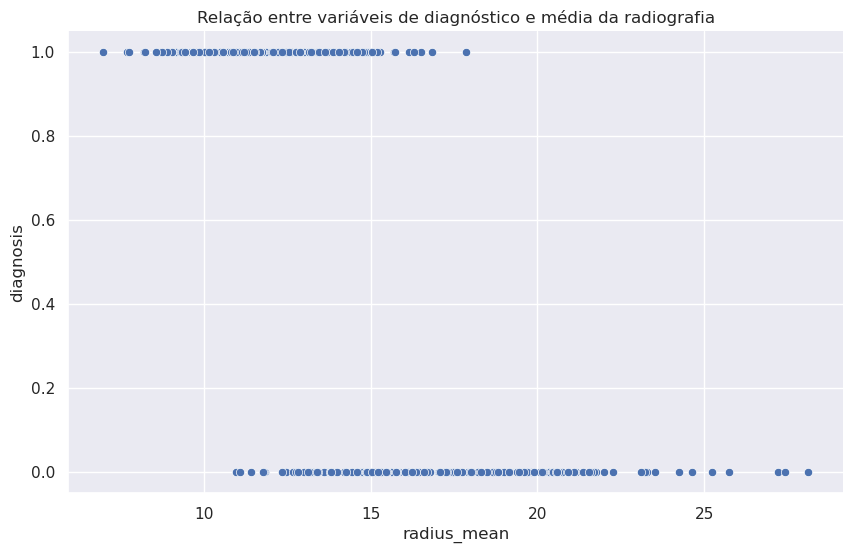

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.set_theme(style='darkgrid')
sns.scatterplot(data=df, x='radius_mean', y='diagnosis', ax=ax)
ax.set_title('Relação entre variáveis de diagnóstico e média da radiografia')
sns.despine(ax=ax)


In [37]:
x = df.drop(columns='diagnosis')
y = df['diagnosis']

x_train, x_test, y_train, y_test  = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y);
LogisticRegressor = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
LogisticRegressor.fit(x_train, y_train)
print(f'Acurácia no treino: {LogisticRegressor.score(x_train, y_train) * 100:.2f}%')
print(f'Acurácia no teste: {LogisticRegressor.score(x_test, y_test) * 100:.2f}%')

Acurácia no treino: 98.90%
Acurácia no teste: 98.25%


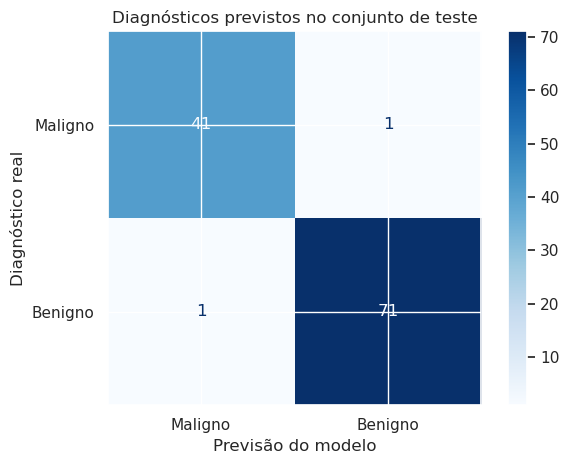

In [44]:

y_pred = LogisticRegressor.predict(x_test)

matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])

grafico = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Maligno', 'Benigno']
)
grafico.plot(cmap='Blues', values_format='d')

plt.title('Diagnósticos previstos no conjunto de teste')
plt.xlabel('Previsão do modelo')
plt.ylabel('Diagnóstico real')
plt.tight_layout()
plt.show()

## Bloco prático ao vivo

Agora vamos implementar e avaliar um classificador de regressão logística durante a aula.

# Regressão Logistica

In [3]:
#Cálculo da sigmoid e modelo linear com python

# Dataset Diagnosis

In [4]:

df = pd.read_csv('datasets/Diagnosis.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
#Formatando dataset

In [6]:
#Gráfico com Diagnosis e Radius_mean

In [7]:
#Treinar Modelo


In [8]:
#Matriz de confusão


In [2]:
# Libs


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Dispositivo:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu
Dispositivo: cpu


### Redes neurais artificiais, neurônios e perceptron
Uma **rede neural artificial** é um modelo computacional inspirado, de forma simplificada, pelo funcionamento de redes de neurônios biológicos. Ela é formada por undiades conectadas que recebem entradas, *combinam essas entradas usando pesos*, e produzem *saídas*. Uma **rede neural artificial** é um modelo computacional inspirado, de forma simplificada, no funcionamento de redes de neurônios biológicos. Ela é formada por unidades conectadas que recebem entradas, combinam essas entradas usando pesos e produzem saídas. Durante o treinamento, os pesos são ajustados para que o modelo faça previsões cada vez mais adequadas aos exemplos observados.

Se isso soa familiar, é por que é mesmo. Em uma perspectiva isolada, *um neurônio é quase igual a uma modelo linear* como os que demonstramos anteriormente, que recebe dados e devolva dados transformados linearmente. Porém, com algumas distinções importantes. A começar que, assim como neurônios cerebrais não trabalham sozinhos, *redes neurais são compostas de vários neurônios encadeados* de modo que trabalhem juntos para se chegar em um resultado. Outra distinção importante, é que os neurônios comumente possuem uma *função de ativação* que introduzem não-linearidade, como explicaremos em breve.


A unidade básica de uma rede neural é o **neurônio artificial**. Para entradas $x_1, x_2, \ldots, x_n$, pesos $w_1, w_2, \ldots, w_n$ e um viés $b$, o neurônio calcula primeiro uma combinação ponderada:

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$

Em seguida, uma função de ativação pode transformar $z$ na saída do neurônio:

$$
a = f(z)
$$

E esta é a estrutura básica de um neurônico artificial. Observe a semelhança com os modelos que já vimos até então.

In [3]:
# Um neurônio artificial: combinacao ponderada, viés e ativação
x = torch.tensor([2.0, 3.0])
pesos = torch.tensor([0.5, -0.25])
vies = torch.tensor(0.1)

z = torch.dot(pesos, x) + vies
saida_relu = torch.relu(z)
saida_sigmoide = torch.sigmoid(z)

print(f"Entrada: {x}")
print(f"Combinacao linear z: {z:.3f}")
print(f"Saida ReLU: {saida_relu:.3f}")
print(f"Saida sigmoide: {saida_sigmoide:.3f}")

Entrada: tensor([2., 3.])
Combinacao linear z: 0.350
Saida ReLU: 0.350
Saida sigmoide: 0.587


### O Perceptron

O **perceptron**, proposto por Frank Rosenblatt no final da década de 1950, foi um dos primeiros modelos de neurônio artificial. Em sua concepção original, o perceptron se assemelhava muito ao modelo de *Regressão Logística*, com a diferença de que usamos uma função de ativação diferente, chamada de *degrau*, enquanto a logística utiliza a sigmoide. Existem mais de um tipo de função degrau, mas a mais conhecida é a *heaviside*:

$$
a = \begin{cases} 1, & \text{se } z \geq 0 \\ 0, & \text{se } z < 0 \end{cases}
$$s.

Note que, usar *um único perceptron* e utilizar uma função de ativação como a *sigmoide* como função de ativação, fará o perceptron agir exatamente como uma regressão logística.

### Por que precisamos de uma função de ativação?

A Álgebra Linear nos fornece as ferramentas necessárias para entender profundamente essa questão, mas de maneira intuitiva, podemos entender que as *transformações lineares* (como o que o neurônio artificial produz) possuem uma importante propriedade: ao serem combinadas, o todo *permanece linear*, isto é, transformações lineares em sequência podem ser representadas como uma única grnade transformação linear. 

Isso é ruim para o modelo, pois 'obriga' o modelo a apenas aprender padrões lineares. Como exemplo didático, imagina que seu modelo quer aprender a classificar imagens: um modelo 100% linear teria, nessas condições, extrema dificuldade para representar curvas suaves, por exemplo.

Assim, aplicamos da *função de ativação* para introduzir não-linearidade entre as *camadas* da rede neural, permitindo que o modelo aprenda padrões mais complexos do que simples relações lineares nos dados.


Algumas funções de ativação comuns são:

- **ReLU:**

$$
\operatorname{ReLU}(z) = \max(0, z)
$$

- **Sigmoide:**

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Entre outras.

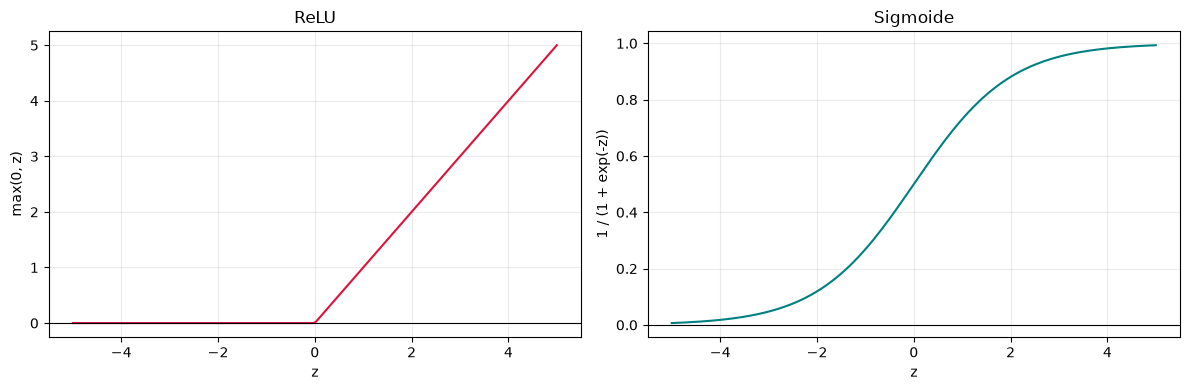

In [4]:
# Comparar as funcoes de ativacao ReLU e sigmoide
valores = torch.linspace(-5, 5, 200)
relu = torch.relu(valores)
sigmoide = torch.sigmoid(valores)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(valores.numpy(), relu.numpy(), color="crimson")
eixos[0].set_title("ReLU")
eixos[0].set_xlabel("z")
eixos[0].set_ylabel("max(0, z)")
eixos[1].plot(valores.numpy(), sigmoide.numpy(), color="teal")
eixos[1].set_title("Sigmoide")
eixos[1].set_xlabel("z")
eixos[1].set_ylabel("1 / (1 + exp(-z))")
for eixo in eixos:
    eixo.axhline(0, color="black", linewidth=0.8)
    eixo.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Camadas e rede de neurônios
Até agora, vimos o que é um neurônio artificial. Porém, um único neurônio artificial isolado não é muito melhor que um modelo de regressão simples. O verdadeiro poder dos neurônios se dá, principalmente, quando eles se unem para formar uma *rede neural*. De forma simplificada, nós temos diferentes tipos de camadas com funções diferentes dentro do modelo de Rede Neural:

#### Características e Vetor de Entrada
Uma **característica** (ou *feature*) é uma informação usada pelo modelo para fazer uma previsão. Por exemplo, se quisermos prever se um estudante será aprovado, podemos usar, por exemplo, *horas de estudo* $(x_1)$ e *número de exercícios resolvidos* $(x_2)$. 
Assim, como cada novo *exemplo*/*observação* (no nosso exemplo, seriam os alunos) possui um conjunto de características, podemos organizar em um *vetor* cada instância de entrada:
$$
x = [x_1, x_2]
$$
Ou seja, o vetor $x$ representa uma observação. Os valores $x_1$ e $x_2$ são as características daquele exemplo.


#### Camada de Entrada
A **camada de entrada** é a porta de entrada dos dados na rede. Ela recebe o vetor de características e encaminha seus valores para a primeira camada de neurônios. Ela é responsável apenas pelo *direcionamento*, dos vetores de entrada para os neurônios das camadas escondidas, e possui tamanho iguala quantidade de características.

#### Camadas Escondidas
A **camada escondida** é intermediária entre a entrada e saída e é onde a mágica realmente acontece. Ela é formada por neurônios, que combinam característias usando pesos e vieses próprios, além de uma função de ativação.

$$
z_j = w_{j1}x_1 + w_{j2}x_2 + b_j
$$

Depois, aplica uma função de ativação:

$$
h_j = f(z_j)
$$

O índice $j$ identifica o neurônio. Como cada neurônio possui pesos diferentes, cada um pode aprender uma combinação diferente das mesmas características. Os valores produzidos nessa etapa são representações intermediárias, por isso não são diretamente os rótulos ou as previsões finais.

#### Camada de Saída
Por fim, A **camada de saída** recebe os valores produzidos pela camada escondida e transforma essa representação no resultado desejado da tarefa. As camadas de saída vão mudar de acordo com o tipo de problema. Por exemplo, em classificação binária, podemos ter apenas um único neurônio de saída. Ele produz um valor chamado **logit**:


$$
z_{saída} = W_2h + b_2
$$

O logit ainda não é uma probabilidade. Quando necessário, usamos a sigmoide para convertê-lo em um valor entre 0 e 1.

In [5]:
# Uma rede pequena: 2 entradas, 4 neuronios escondidos e 1 saida
rede = nn.Sequential(
    nn.Linear(2, 4),
    nn.ReLU(),
    nn.Linear(4, 1),
)

entrada_exemplo = torch.tensor([[6.0, 20.0]])
logit_exemplo = rede(entrada_exemplo)
probabilidade_exemplo = torch.sigmoid(logit_exemplo)

print(rede)
print("Formato da entrada:", entrada_exemplo.shape)
print("Formato do logit:", logit_exemplo.shape)
print("Probabilidade inicial:", probabilidade_exemplo.item())

Sequential(
  (0): Linear(in_features=2, out_features=4, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=1, bias=True)
)
Formato da entrada: torch.Size([1, 2])
Formato do logit: torch.Size([1, 1])
Probabilidade inicial: 0.9991669654846191


#### Feedforward
O ato de inicializar os valores para todos os pesos e vieses de todos os neurônios, e avançar pela primeira iteração completa do modelo até o final (mesmo com os pesos geralmente iguais a zero), é chamado de *feedforward* ou *passada para frente*. Isso irá gerar um resultado dado pela *camada de saída*, que muito provavelmente será uma péssima resposta, pois teremos que treinar o modelo a ficar melhor, ajustando seus pesos e vieses.

In [6]:
# Forward propagation passo a passo para um unico exemplo
# (altamente recomendável estudar Álgebra Linear e Cálculo para entender o que está acontecendo aqui)

entrada = torch.tensor([[6.0, 20.0]])
pesos_escondidos = torch.tensor([
    [0.8, 0.1],
    [0.2, 0.7],
    [-0.5, 0.3],
    [0.4, -0.2],
])
vieses_escondidos = torch.tensor([[0.1, -0.4, 0.2, 0.0]])
pesos_saida = torch.tensor([[0.6], [-0.3], [0.4], [0.5]])
vies_saida = torch.tensor([[0.2]])

z_escondido = entrada @ pesos_escondidos.T + vieses_escondidos
h = torch.relu(z_escondido)
logit = h @ pesos_saida + vies_saida
probabilidade = torch.sigmoid(logit)

print("z da camada escondida:", z_escondido)
print("h apos ReLU:", h)
print("logit da saida:", logit.item())
print("probabilidade final:", probabilidade.item())

z da camada escondida: tensor([[ 6.9000, 14.8000,  3.2000, -1.6000]])
h apos ReLU: tensor([[ 6.9000, 14.8000,  3.2000,  0.0000]])
logit da saida: 1.1800003051757812
probabilidade final: 0.7649478912353516


### Função de Custo, Backpropagation e Treinamento -- como modelos 'Aprendem'
A forward propagation produz uma previsão, mas ainda precisamos medir se ela está boa. A **função de custo** (ou função de perda), assim como nos modelos clássicos anteriores que vimos, compara a previsão $\hat{y}$ com o valor correto $y$ e transforma essa diferença em um número. Quanto menor o custo, mais próximas estão as previsões dos rótulos esperados.

Para uma classificação binária, uma escolha comum é a **entropia cruzada binária** (*Binary Cross-Entropy*), que nós já vimos:

$$
J = -\frac{1}{m}\sum_{i=1}^{m}\left[y_i\log(\hat{y}_i) + (1-y_i)\log(1-\hat{y}_i)\right]
$$

A fórmula penaliza previsões confiantes e erradas. Por exemplo, quando $y=1$, uma probabilidade próxima de 1 gera custo baixo; uma probabilidade próxima de 0 gera custo alto.

Lembra do que falamos na ``aula 1`` sobre **Derivadas** e **Gradiente Descente**? Nas redes neurais, utilizamos esses dois conceitos extensivamente, e junto de um algoritmo chamado *autodiff* que tornou as redes neurais computacionalmente viáveis (veja o material auxiliar), podemos aplicar o que chamamos de **Backpropagation** ou *retropropagação*, que é a chave do qual como redes neurais 'aprendem' os dados.

### Retropropagação
A *Regra da Cadeia*, um importante conceito de Cálculo Diferencial, permite o modelo saber exatamente *o quanto cada peso e viés dos neurônios contribuiu para aquela perda*, fazendo uma espécie de "mapa" de pesos e vieses importantes para que a função de perda pode ser minimizada.

Com essa ferramenta em mãos, o modelo 'anda pra trás', descobrindo, para cada camada, quais foram os pesos que mais influenciaram para gerar aquele erro observado específico, até que, no final, tenhamos os *gradientes* para cada parâmetro: isto é, para cada parâmetro, teremos um *vetor* que aponta para a direção de onde a função de custo vai *aumentar* caso nós alteremos os pesos e vieses.

### Otimizador
Finalmente, podemos aplicar o *Gradiente Descente* tal qual como aprendemos na primeira aula: agora que já temos os gradientes do modelo, podemos ir na direção oposta do vetor de todos os gradientes, multiplicando pela *taxa de aprendizado*, gerando um novo vetor de parâmetros que andou "um pouco em direção a menor função de custo possível", e podemos atualizar nossa rede com esses novos parâmetros.

O treinamento usa os gradientes para atualizar os parâmetros com o gradiente descendente:

$$
\theta \leftarrow \theta - \eta\nabla_{\theta}J
$$

Aqui, $\theta$ representa todos os pesos e vieses, $\eta$ é a taxa de aprendizado e $\nabla_{\theta}J$ é o gradiente do custo em relação aos parâmetros.

O ciclo completo de treinamento é:

1. realizar a forward propagation;
2. calcular a função de custo;
3. zerar gradientes antigos;
4. executar o backpropagation;
5. atualizar os parâmetros;
6. repetir por várias épocas.

Uma **época** corresponde a uma passagem pelo conjunto de treinamento. Em conjuntos grandes, os exemplos são divididos em lotes (*batches*), e os parâmetros são atualizados após cada lote.

In [7]:
# A funcao BCEWithLogitsLoss combina sigmoid e entropia cruzada com estabilidade numerica
logits = torch.tensor([2.0, -1.0, 0.2], requires_grad=True)
rótulos = torch.tensor([1.0, 0.0, 1.0])
funcao_custo = nn.BCEWithLogitsLoss()
perda = funcao_custo(logits, rótulos)
perda.backward()

print(f"Perda: {perda.item():.4f}")
print("Gradientes dos logits:", logits.grad)

# Um passo de gradiente descendente em um parametro escalar
parametro = torch.tensor(2.5, requires_grad=True)
custo_parametro = parametro ** 2
custo_parametro.backward()
with torch.no_grad():
    parametro -= 0.2 * parametro.grad
print(f"Parametro depois de um passo: {parametro.item():.2f}")

Perda: 0.3461
Gradientes dos logits: tensor([-0.0397,  0.0896, -0.1501])
Parametro depois de um passo: 1.50


### Exemplo de Rede Neural simples

Agora vamos reunir os conceitos anteriores em uma rede neural pequena para um problema de classificação binária. Iremos usar o mesmo exemplo de avaliação se um aluno passou ou reprovou.

A rede terá:

- duas entradas, uma para cada característica;
- uma camada escondida com quatro neurônios;
- uma função de ativação ReLU na camada escondida;
- um neurônio de saída, que produzirá um logit;
- uma sigmoide na etapa de previsão para obter uma probabilidade.

A arquitetura pode ser representada assim:

$$
X \rightarrow Linear(2, 4) \rightarrow ReLU \rightarrow Linear(4, 1)
$$

Os rótulos serão `0` para reprovado e `1` para aprovado. Durante o treinamento, a rede fará previsões, calculará a Binary Cross-Entropy, obterá os gradientes com backpropagation e atualizará seus parâmetros com um otimizador.

In [8]:
# 1. Gerar dados sintéticos
rng = np.random.default_rng(42)

# Cada aluno tem duas características:
# - Horas de estudo: valor contínuo entre 0 e 10
# - Exercícios resolvidos: número inteiro entre 0 e 50
horas_estudo = rng.uniform(0, 10, size=240)
exercicios_resolvidos = rng.integers(0, 51, size=240)

Perda inicial: 0.7001
Perda final: 0.3293
Acurácia nos dados de treinamento: 0.867


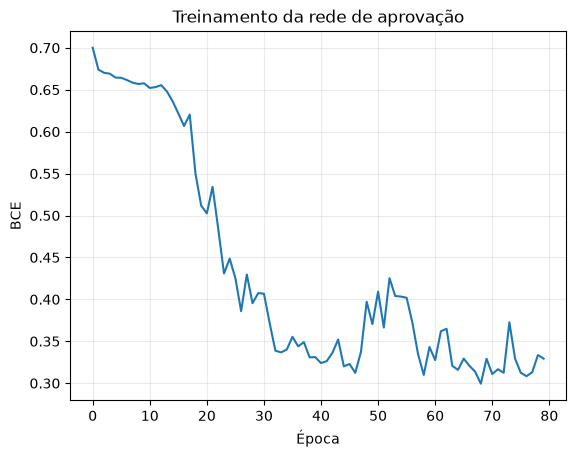

In [9]:
# Matriz de características: 240 alunos x 2 características
caracteristicas = np.column_stack([
    horas_estudo,
    exercicios_resolvidos
]).astype(np.float32)

# 2. Gerar os rótulos: 0 = reprovado, 1 = aprovado
ruido = rng.normal(0, 0.8, size=240)

resultado = (
    horas_estudo * 0.5
    + exercicios_resolvidos * 0.1
    + ruido
    > 5.5
).astype(np.float32)

# 3. Converter os dados para tensores PyTorch
x_alunos = torch.tensor(caracteristicas, dtype=torch.float32)
y_alunos = torch.tensor(resultado, dtype=torch.float32).unsqueeze(1)

# 4. Criar dataset e DataLoader
dataset_alunos = TensorDataset(x_alunos, y_alunos)

loader_alunos = DataLoader(
    dataset_alunos,
    batch_size=32,
    shuffle=True
)

# 5. Definir a rede neural
modelo_alunos = nn.Sequential(
    nn.Linear(2, 4),  # 2 entradas -> 4 neurônios ocultos
    nn.ReLU(),
    nn.Linear(4, 1)   # 4 valores -> 1 saída
)

# 6. Definir a função de perda e o otimizador
perda_alunos = nn.BCEWithLogitsLoss()

otimizador_alunos = torch.optim.Adam(
    modelo_alunos.parameters(),
    lr=0.03
)

historico_perdas = []

# 7. Treinar a rede neural
for epoca in range(80):
    perda_epoca = 0.0

    for lote_x, lote_y in loader_alunos:
        # Limpar os gradientes anteriores
        otimizador_alunos.zero_grad()

        # Forward propagation: calcular as saídas
        logits_lote = modelo_alunos(lote_x)

        # Calcular a perda comparando previsões e rótulos
        perda = perda_alunos(logits_lote, lote_y)

        # Backpropagation: calcular os gradientes
        perda.backward()

        # Atualizar pesos e vieses
        otimizador_alunos.step()

        # Acumular a perda ponderada pelo tamanho do lote
        perda_epoca += perda.item() * len(lote_x)

    # Perda média da época
    historico_perdas.append(
        perda_epoca / len(dataset_alunos)
    )

# 8. Avaliar a rede nos dados de treinamento
modelo_alunos.eval()

with torch.no_grad():
    logits = modelo_alunos(x_alunos)
    probabilidades = torch.sigmoid(logits)
    previsoes = (probabilidades >= 0.5).float()

    acuracia = (previsoes == y_alunos).float().mean().item()

# 9. Exibir resultados
print(f"Perda inicial: {historico_perdas[0]:.4f}")
print(f"Perda final: {historico_perdas[-1]:.4f}")
print(f"Acurácia nos dados de treinamento: {acuracia:.3f}")

# 10. Visualizar a evolução da perda
plt.plot(historico_perdas)
plt.xlabel("Época")
plt.ylabel("BCE")
plt.title("Treinamento da rede de aprovação")
plt.grid(alpha=0.25)
plt.show()

### Aprendizado Profundo

**Aprendizado profundo** (*deep learning*) é o uso de redes neurais com várias camadas de processamento. A palavra "profundo" se refere à quantidade de camadas entre a entrada e a saída, e não significa *necessariamente* que o modelo será melhor ou mais inteligente.

Em uma rede rasa, a entrada passa por poucas transformações. Em uma rede profunda, cada camada pode aprender uma representação intermediária diferente:

As primeiras camadas podem aprender padrões mais simples. Em imagens, por exemplo, podem responder a bordas e formas básicas; em textos, podem capturar relações entre palavras. Camadas posteriores combinam essas representações para formar padrões mais abstratos e úteis para a tarefa.

A profundidade aumenta a capacidade de representação do modelo, mas também pode tornar o treinamento mais difícil. Redes profundas podem exigir mais dados, mais memória, mais tempo de treinamento e técnicas como inicialização adequada, normalização e regularização.

In [10]:
# Comparar uma rede rasa e uma rede profunda
rede_rasa = nn.Sequential(
    nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1)
)
rede_profunda = nn.Sequential(
    nn.Linear(2, 8), nn.ReLU(),
    nn.Linear(8, 8), nn.ReLU(),
    nn.Linear(8, 8), nn.ReLU(),
    nn.Linear(8, 1),
)

parametros_rasa = sum(parametro.numel() for parametro in rede_rasa.parameters())
parametros_profunda = sum(parametro.numel() for parametro in rede_profunda.parameters())
print(f"Parametros na rede rasa: {parametros_rasa}")
print(f"Parametros na rede profunda: {parametros_profunda}")

with torch.no_grad():
    saida_rasa = torch.sigmoid(rede_rasa(x_alunos[:5])).squeeze()
    saida_profunda = torch.sigmoid(rede_profunda(x_alunos[:5])).squeeze()
print("Saidas iniciais da rede rasa:", saida_rasa)
print("Saidas iniciais da rede profunda:", saida_profunda)

Parametros na rede rasa: 33
Parametros na rede profunda: 177
Saidas iniciais da rede rasa: tensor([0.8081, 0.9997, 0.7029, 0.9994, 0.9907])
Saidas iniciais da rede profunda: tensor([0.4165, 0.4368, 0.4185, 0.4299, 0.4322])


## Introdução a IA Moderna
O Aprendizado Profundo se tornou cada vez mais viável e mais interessante para os pesquisadores a medida em que se avançou com as tecnologias e com as ferramentas computacionais. A capacidade computacional aumentou e os modelos aumentaram junto. A medida em que os modelos foram ficando cada vez maiores e mais sofisticados, *padrões cada vez mais complexos* passaram a ser possíveis, e incluindo novas formas não antes imaginadas de se aplicar aprendizado de máquina foram surgindo.

A medida em que começamos a treinar modelos para fazer tarefas fora do convencional (de usar números para cuspir números), como *classificar imagens* ou *analisar textos*, descobrimos um grande universo de possibilidades possíveis que transformaram radicalmente o mundo em que conhecemos. 

Chamamos de **Inteligência Artificial moderna** o conjunto de técnicas, modelos e sistemas que se beneficiaram dessa capacidade de representação de grandes volumes de dados e de maior poder computacional. GPUs e outros aceleradores tornam possível treinar redes com muitos parâmetros; arquiteturas especializadas ajudam a processar imagens, áudio, texto e outros tipos de informação.

A IA moderna possui muitos exemplos de aplicação: visão computacional, reconhecimento de fala, recomendação, robótica, previsão de séries temporais e geração de conteúdo, entre outros. Neste final de aula, não estudaremos todos eles. Vamos acompanhar **um exemplo de aplicação**, entre vários possíveis: o **Processamento de Linguagem Natural (PLN)**, área que trabalha com textos e linguagem humana.

### Processamento de Lingugem Natural
A linguagem humana é extremamente complexa, muitas vezes além da nossa compreensão trivial. Uma sequência de palavras pode ter significados diferentes se encaixados em outras sequências de palavras (a maldição do "Contexto", e como LLMs buscam resolver isso), algumas palavras possuem significados metafóricos em diferentes ocasiões, pessoas diferentes escrevem de maneira diferentes, existem contrações, jargões, aforismos, palavrões, gírias, entre muitos outros problemas.

Assim sendo, como somos capazes de treinar modelos de aprendizado de máquina capazes de dominar algo tão complexo quanto a linguagem humana?

Nesta aula, abordaremos de forma *rápida* alguns tópicos fundamentais para entender como IAs modernas funcionam, sem se apegar muito extensivamente aos detalhes de seu funcionamento:
- *Embeddings*, e como representar texto.
- O que são *Transformers* e *Atenção*
- Aplicando os conceitos.

### O que é uma LLM?

**LLM** significa *Large Language Model*, ou grande modelo de linguagem. É uma rede neural profunda treinada com muitos textos para aprender padrões de uma língua e estimar qual *token* (pense em 'palavras', por enquanto) tem maior probabilidade de aparecer depois de uma sequência.

Durante a geração, o modelo recebe um contexto, calcula probabilidades para o próximo token, escolhe um token e repete o processo. Transformers usam *embeddings* e *atenção* para considerar as relações entre os tokens do contexto.

Iremos ver brevemente como isso funciona.

### Embeddings
Computadores trabalham diretamente com números, mas textos, imagens e outros dados chegam inicialmente em formatos simbólicos que o computador não necessariamente sabe lidar. Textos, por exemplo, podem parecer uma mera *sequência de letras*, mas não são: essa mesma sequência de letras pode ter significados diferentes perto de outras sequências de letras, e vice-versa.

Assim, precisamos de uma maneira de representar palavras e sua complexidade usando números que uma rede neural, por exemplo, entenda. A primeira parte pode ser feita usando um **tokenizador**, e a segunda parte, usando *embeddings*.

**Tokenização** é o processo de dividir uma sequência em unidades menores chamadas *tokens*. Dependendo do tokenizador, um token pode ser uma palavra, parte de uma palavra, um sinal de pontuação, um espaço ou um símbolo especial. Um bom exemplo do por que usar *tokens* e não palavras ou sílabas inteiras pode ser a palavra `Don't`, do inglês. Apesar de ser uma abreviação de **Do not** (não faça), a palavra é comum o suficiente para aparecer na maioria dos textos em sua forma contracionada. Um tokenizador poderia criar dois tokens com essa palavra:

*   `Do`: fazer
*   `n't`: "negar o verbo anterior"

Assim, poderíamos *reutilizar* o token `n't` em outras situações, mantendo o significado coerente, e sem ter que criar vários tokens pra variações de uma mesma palavra.

A tokenização ajuda, mas ainda não resolve o problema da complexidade semântica da linguagem natural. Por exemplo, sabemos qeu `gato` e `cachorro` são animais e estão relacionados em algumas características (como ter 4 patas e serem domesticáveis), e em outras, não (estrutura óssea, por exemplo). Como representar numericamente essas diferenças e semelhanças?
De forma semelhante aos problemas anteriores que resolvemos, a solução aqui é a uma *rede neural profunda*. Vamos acompanhar o processo.

Depois da tokenização, cada token recebe um índice inteiro em um vocabulário de tokens. Por exemplo:

$$
[\text{O},\text{gato},\text{dormiu}]\rightarrow[0,1,4]
$$

Observe que esses índices são arbitrários por enquanto, e estamos assumindo no exemplo acima que cada palavra virou um token.

Agora, como poderíamos representar a *informação* que cada token transmite *em relação ao seu próprio vocabulário*? Faremos isso usando vetores, e tem duas formas principais de fazer isso.

#### Representação One-Hot
Na representação *one-hot*, usamos *vetores esparsos* (vetores onde a maioria dos elementos são 0) para representar cada token em relação ao seu vocabulário. A ideia é simples: usando o *índice* como referência, nós criaremos um vetor com quantidade de elementos igual ao tamanho total do vocabulário, e marcaremos com "1" onde nosso token está no vocabulário, e "0" em todas outras posições. Por exemplo, para um vocabulário com apenas 3 palavras, `gato`, `cachorro` e `carro`:

$$
\begin{aligned}
\text{gato }(0)&\rightarrow[1,0,0]\\
\text{cachorro }(1)&\rightarrow[0,1,0]\\
\text{carro }(2)&\rightarrow[0,0,1]\\
\end{aligned}
$$

Essa forma de representação pode ser muito poderosa em alguns contextos, especialmente em *mecanismos de busca*, porém, são insuficiente para representar a *similaridade semântica* entre as palavras. Por exemplo, gato e cachorro estão claramente relacionados, mas os vetores $[1,0,0]$ e $[0,1,0]$ não necessariamente estão relacionados. Para isso, usaremos uma representação via *embeddings*, que criará, para cada token, um *vetor denso* (a maioria dos valores não são zeros) chamado *embedding* pra cada token:

#### Embeddings e Representação Semântica
Criando um vetor denso pra cada token no vocabulário, podemos ter algo semelhante a isso:

$$
e_{\text{gato}}=[0.80,0.70],\qquad e_{\text{cachorro}}=[0.75,0.72]
$$

Note que, nesse exemplo, as palavras `gato` e `cachorro` parecem possuir uma certa *similaridade*, ambos possuem valores relativamente próximos em seus vetores na coluna 1 e 2 do embedding. Porém, como chegamos nesses valores para os embeddings? é aí que entra as *redes neurais profundas*.
Para criar nossos embeddings, treinamos redes neurais profundas com base em **grandes quantidades de texto**, e testamos o modelo dando a ele frases incompletas e pedindo-o para completar, recompensando automaticamente o modelo quando seus pesos tornaram as previsões mais precisas.

Isso, apesar de não *garantir embeddings semânticos** (isso é um tópico que logo veremos) perfeitamente, essa representação já faz com que frases estruturalmente corretas sejam muito mais prováveis de aparecerem, mesmo que não façam total sentido semântico ainda. Por exemplo, um modelo treinado poderia criar embeddings e permitir frases como:

*   `O rato correu`
*   `A cobra sibilou`

E teria muito menos chances de gerar frases como:

*   `A cobra sofá`

Por que a palavra "sofá" teria uma incidência baixíssima em sequência da palavra 'cobra', e o modelo poderia aprender, em suas várias camadas ocultas, as diferenças gramaticais entre sujeito, verbo, substantivos, e etc.

Vetores próximos podem ajudar o modelo a representar relações úteis. As dimensões não devem ser interpretadas automaticamente como características humanas isoladas; a informação costuma estar distribuída pelo vetor inteiro.

Os embeddings ficam armazenados em uma matriz treinável. Se o vocabulário tem $V$ tokens e cada vetor possui $d$ dimensões, então:

$$
E\in\mathbb{R}^{V\times d}
$$


Cada linha corresponde ao vetor de um token. Durante o treinamento, a retropropagação calcula gradientes e o otimizador ajusta também os valores dessa matriz.

E então podemos adotar uma forma de comparar embeddings, como a a similaridade de cosseno:

$$
\operatorname{cos}(u,v)=\frac{u\cdot v}{\|u\|\|v\|}
$$

Valores próximos de 1 indicam direções parecidas; próximos de 0 indicam vetores ortogonais. Essa medida pode encontrar elementos relacionados, mas não é uma medida perfeita de significado e depende dos dados e do treinamento.

Embeddings **estáticos**, como os de Word2Vec e GloVe, associam um vetor fixo a cada token. Em modelos baseados em Transformers, o embedding inicial é combinado com os *demais tokens da sequência*, adicionando mais contexto e semântica para os embeddings.

Portanto, o embedding inicial é apenas o ponto de partida. As camadas da rede produzem representações contextuais mais ricas, que podem ser usadas na tarefa aprendida:

Tokens: ['gato', 'corre', 'animal']
Indices: [0, 3, 2]
Formato dos embeddings: (3, 3)
Similaridade inicial entre 'gato' e 'animal': 0.325


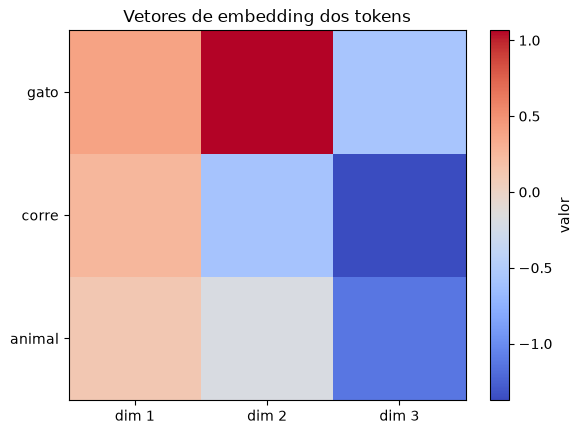

In [11]:
# Tokens, indices e uma tabela de embeddings treinavel
vocabulario = {"gato": 0, "cachorro": 1, "animal": 2, "corre": 3}
tokens = ["gato", "corre", "animal"]
indices = torch.tensor([vocabulario[token] for token in tokens])

# Cada linha corresponde ao vetor de um token
embeddings = nn.Embedding(num_embeddings=len(vocabulario), embedding_dim=3)
vetores = embeddings(indices)

similaridade = nn.functional.cosine_similarity(vetores[0], vetores[2], dim=0)
print("Tokens:", tokens)
print("Indices:", indices.tolist())
print("Formato dos embeddings:", tuple(vetores.shape))
print(f"Similaridade inicial entre 'gato' e 'animal': {similaridade.item():.3f}")

plt.imshow(vetores.detach().numpy(), aspect="auto", cmap="coolwarm")
plt.xticks(range(vetores.shape[1]), ["dim 1", "dim 2", "dim 3"])
plt.yticks(range(len(tokens)), tokens)
plt.colorbar(label="valor")
plt.title("Vetores de embedding dos tokens")
plt.show()

### TF-IDF

Antes de avançarmos para Transformers, vamos conhecer uma forma clássica de transformar textos em números: o **TF-IDF** (*Term Frequency–Inverse Document Frequency*), que será utilizado nesta mesma aula para treinarmos uma rede neural.
O **TFIIDF** parte de uma premissa simples: *uma palavra que aparece muito no documento é importante*, porém, se a palavra *aparece demais em todo documento*, ela provavelmente é menos informativa (exemplo, artigos definidos e indefinidos como e, o, um, os). Assim, ele pondera a **frequência do termo** pela **frequência inversa nos documentos** do termo.

A **frequência do termo** (*TF*) mede a presença da palavra no documento:

$$
\operatorname{TF}(t,d)=\frac{\text{quantidade de ocorrências de }t\text{ em }d}{\text{quantidade total de termos em }d}
$$

A **frequência inversa nos documentos** (*IDF*) reduz o peso de palavras que aparecem em muitos documentos (como artigos). Na versão suavizada usada pelo `scikit-learn`, temos:

$$
\operatorname{IDF}(t)=\log\left(\frac{1+N}{1+\operatorname{df}(t)}\right)+1
$$

Aqui, $N$ é o número total de documentos e $\operatorname{df}(t)$ é o número de documentos que contêm o termo $t$. Finalmente, o peso TF-IDF é calculado por:

$$
\operatorname{TF-IDF}(t,d)=\operatorname{TF}(t,d)\times\operatorname{IDF}(t)
$$

Assim, uma palavra comum em todos os textos, como `o` ou `de`, recebe pouco peso. Já uma palavra frequente em um documento, mas rara na coleção, recebe um peso maior. O resultado é um vetor numérico para cada documento, que pode ser usado por modelos de aprendizado de máquina, como no classificador de sentimentos aplicado mais adiante.

### Introdução a Transformers e Attention
Embeddings gerados por redes neurais recorrentes ou outros tipos são poderosos, porém tem suas limitações. A principal limitação é que, os métodos tradicionais de treinamento vão acabar gerando *vetores estáticos* para cada token. Imagine o seguinte exemplo:

*   O `banco` fechou mais cedo hoje
*   Eu sentei no `banco` da praça.

Note que ambas as frases usam uma mesma palavra, 'banco', PORÉM, as duas palavras banco são radicalmente diferentes e o contexto das outras palavras nos permite absorver o verdadeiro significado de 'banco', segundo o contexto.

A ideia central da arquitetura de redes neurais para processamento de linguagem natural **Transformers**, que surgiu com o lendário artigo *Attention is All you Need** (Vaswani et al. 2017), é permitir que cada token **considere os outros tokens na sequência** antes de construir sua própria representação.

Esse mecanismo é chamado de **self-attention** (autoatenção), indicando que a sequência olha a si mesma: cada token compara sua representação com as representações dos outros tokens, incluindo sua própria, pra descobrir quais relações são mais relevantes.

Uma forma intuitiva de entender esse processo é pensar que cada token participa de três papéis:

- **Query (consulta):** o que este token está procurando no contexto?
- **Key (chave):** que tipo de informação este token oferece para ser encontrado?
- **Value (valor):** qual informação será efetivamente utilizada se este token receber atenção?

As consultas e as chaves são comparadas por meio de um produto interno. Quanto maior a pontuação entre uma consulta e uma chave, maior tende a ser a relevância daquele token para a representação que está sendo construída. Depois, essas pontuações são normalizadas pelo `softmax` e usadas para combinar os valores:

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V
$$

Nessa expressão, $Q$, $K$ e $V$ são as matrizes de consultas, chaves e valores, e $d_k$ é a quantidade de dimensões das chaves. A divisão por $\sqrt{d_k}$ evita que os produtos internos fiquem grandes demais quando os vetores possuem muitas dimensões. O `softmax` transforma as pontuações em pesos que somam 1, como se fossem uma distribuição de importância sobre os tokens da sequência.

Em termos intuitivos, cada token faz uma pergunta parecida com: **“quais outros tokens devo considerar para construir uma representação melhor de mim mesmo neste contexto?”**. A resposta é uma combinação ponderada das informações oferecidas pelos demais tokens. Por isso, os embeddings iniciais podem ser transformados em representações **contextuais**: o mesmo token pode assumir representações diferentes dependendo das palavras que aparecem ao seu redor.

A atenção é o mecanismo central dos Transformers. Uma arquitetura Transformer completa também organiza várias camadas desse mecanismo, normalmente combinadas com redes neurais, conexões residuais e informações sobre a posição dos tokens. Nesta introdução, vamos nos concentrar apenas no núcleo da ideia: calcular relações entre tokens e combinar suas informações.

No exemplo seguinte, usaremos uma sequência curta em que $Q$, $K$ e $V$ são a própria representação de entrada. Isso não representa todo o treinamento de um Transformer, mas permite visualizar as pontuações, os pesos de atenção e a saída combinada passo a passo.

Pontuacoes QK^T / sqrt(d_k):
tensor([[1.0000, 0.5000, 0.5000],
        [0.5000, 1.0000, 0.5000],
        [0.5000, 0.5000, 1.5000]])
Pesos de atencao (cada linha soma 1):
tensor([[0.4520, 0.2740, 0.2740],
        [0.2740, 0.4520, 0.2740],
        [0.2120, 0.2120, 0.5760]])
Saida combinada:
tensor([[0.7260, 0.5480, 0.7260, 0.2740],
        [0.5480, 0.7260, 0.7260, 0.2740],
        [0.7880, 0.7880, 0.4240, 0.5760]])


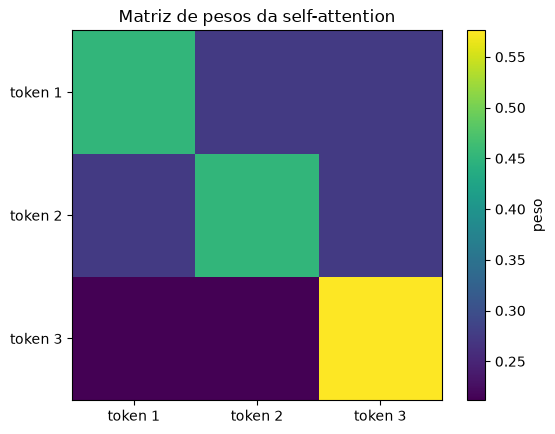

In [12]:
# Self-attention escalada em uma sequencia curta
sequencia = torch.tensor([
    [1.0, 0.0, 1.0, 0.0],
    [0.0, 1.0, 1.0, 0.0],
    [1.0, 1.0, 0.0, 1.0],
])

# Neste exemplo didatico, Q, K e V sao a propria representacao de entrada
query = sequencia
key = sequencia
value = sequencia
dimensao_key = key.shape[-1]

pontuacoes = query @ key.T / np.sqrt(dimensao_key)
pesos_atencao = torch.softmax(pontuacoes, dim=-1)
saida_atencao = pesos_atencao @ value

print("Pontuacoes QK^T / sqrt(d_k):")
print(pontuacoes.round(decimals=3))
print("Pesos de atencao (cada linha soma 1):")
print(pesos_atencao.round(decimals=3))
print("Saida combinada:")
print(saida_atencao.round(decimals=3))

plt.imshow(pesos_atencao.numpy(), cmap="viridis")
plt.xticks(range(3), ["token 1", "token 2", "token 3"])
plt.yticks(range(3), ["token 1", "token 2", "token 3"])
plt.colorbar(label="peso")
plt.title("Matriz de pesos da self-attention")
plt.show()

### LLMs e ChatGPT

**LLM** significa *Large Language Model*, ou grande modelo de linguagem. É um modelo treinado para aprender padrões estatísticos de uma linguagem e, em muitos casos, prever o próximo token de uma sequência.

Em uma formulação autorregressiva, dado um contexto de tokens $x_1, x_2, \ldots, x_t$, o modelo estima uma distribuição para o próximo token:

$$
P(x_{t+1}\mid x_1, x_2, \ldots, x_t)
$$

Durante a geração, um token é escolhido, anexado ao contexto e usado para prever o próximo. Esse processo se repete até que o modelo atinja um token de parada ou o limite definido. A saída é produzida passo a passo, mesmo que o usuário perceba a resposta como um texto único.

O treinamento de um LLM costuma envolver uma grande quantidade de dados e parâmetros. No pré-treinamento, o modelo aprende a prever tokens e ajusta seus parâmetros para reduzir a função de custo. Depois, ele pode passar por etapas adicionais para seguir instruções, adaptar-se a tarefas específicas e melhorar sua utilidade em conversas.

O **ChatGPT** é uma aplicação conversacional baseada em modelos de linguagem da família GPT (*Generative Pre-trained Transformer*). O modelo recebe uma sequência de mensagens como contexto e gera uma continuação token por token. A aplicação ao redor do modelo também pode incluir instruções, histórico da conversa, filtros, ferramentas e outras regras de produto.

É importante distinguir o modelo da interface. Um LLM é o componente que calcula distribuições e gera tokens; um sistema como um chatbot combina esse modelo com uma interface e mecanismos adicionais para organizar a interação.

Um LLM não consulta automaticamente uma fonte de verdade universal. Ele gera respostas com base nos padrões aprendidos e no contexto disponível. Por isso, pode produzir informações incorretas, inventar referências ou apresentar uma resposta plausível com excesso de confiança. A verificação é especialmente importante em temas técnicos, científicos, jurídicos, médicos e em qualquer situação de alto impacto.

A avaliação de um sistema conversacional deve considerar mais do que fluência. Também precisamos observar factualidade, coerência, segurança, privacidade, robustez a instruções inadequadas, vieses e capacidade de reconhecer incerteza.

# Modelo de Rede Neural Completo

In [16]:
# Classificacao de sentimentos no dataset real IMDB
# Usamos TF-IDF para transformar textos em vetores e uma rede neural para classificar 0/1.
imdb = load_dataset("stanfordnlp/imdb")
quantidade_treino = 2500
quantidade_teste = 800
amostra_treino = imdb["train"].shuffle(seed=SEED).select(range(quantidade_treino))
amostra_teste = imdb["test"].shuffle(seed=SEED).select(range(quantidade_teste))

In [19]:
vetorizador = TfidfVectorizer(
    max_features=6000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)

x_treino_np = vetorizador.fit_transform(amostra_treino["text"]).astype(np.float32).toarray()
x_teste_np = vetorizador.transform(amostra_teste["text"]).astype(np.float32).toarray()
y_treino_np = np.asarray(amostra_treino["label"], dtype=np.float32).reshape(-1, 1)
y_teste_np = np.asarray(amostra_teste["label"], dtype=np.float32).reshape(-1, 1)

x_treino = torch.from_numpy(x_treino_np)
y_treino = torch.from_numpy(y_treino_np)
x_teste = torch.from_numpy(x_teste_np)
y_teste = torch.from_numpy(y_teste_np)

loader_imdb = DataLoader(TensorDataset(x_treino, y_treino), batch_size=64, shuffle=True)

In [ ]:
# Instancia a rede
modelo_imdb = nn.Sequential(
    nn.Linear(x_treino.shape[1], 64),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(64, 1),
)

perda_imdb = nn.BCEWithLogitsLoss()
otimizador_imdb = torch.optim.Adam(modelo_imdb.parameters(), lr=0.001)
historico_imdb = []

In [22]:
# Treinar o modelo
for epoca in range(4):
    modelo_imdb.train()
    soma_perdas = 0.0
    for lote_x, lote_y in loader_imdb:
        otimizador_imdb.zero_grad()
        logits = modelo_imdb(lote_x)
        perda = perda_imdb(logits, lote_y)
        perda.backward()
        otimizador_imdb.step()
        soma_perdas += perda.item() * len(lote_x)
    perda_media = soma_perdas / len(loader_imdb.dataset)
    historico_imdb.append(perda_media)
    print(f"Epoca {epoca + 1}: perda = {perda_media:.4f}")

Epoca 1: perda = 0.6769
Epoca 2: perda = 0.5815
Epoca 3: perda = 0.4414
Epoca 4: perda = 0.3219


Vocabulário TF-IDF: 6000 termos
Acurácia no teste IMDB: 0.838


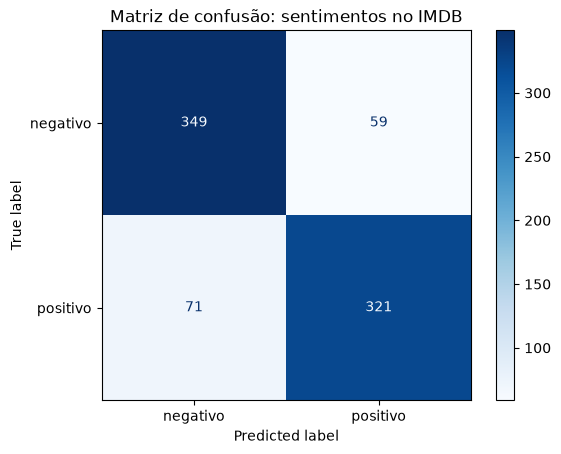

In [24]:
modelo_imdb.eval()
with torch.no_grad():
    probabilidades_imdb = torch.sigmoid(modelo_imdb(x_teste)).squeeze(1).numpy()
previsoes_imdb = (probabilidades_imdb >= 0.5).astype(int)
rótulos_imdb = y_teste.squeeze(1).numpy().astype(int)
acuracia_imdb = accuracy_score(rótulos_imdb, previsoes_imdb)
matriz_imdb = confusion_matrix(rótulos_imdb, previsoes_imdb)

print(f"Vocabulário TF-IDF: {len(vetorizador.vocabulary_)} termos")
print(f"Acurácia no teste IMDB: {acuracia_imdb:.3f}")
ConfusionMatrixDisplay(matriz_imdb, display_labels=["negativo", "positivo"]).plot(cmap="Blues")
plt.title("Matriz de confusão: sentimentos no IMDB")
plt.show()